In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")



Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:

df = pd.read_csv("../dataset/European_Bank.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print("Total Customers:")
df.shape[0]
print("Total Columns:", df.shape[1])

Total Customers:
Total Columns: 14


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [6]:
print("Missing Value:")
print(df.isnull().sum())

Missing Value:
Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [7]:
print("Duplicate Rows:",
df.duplicated().sum())

Duplicate Rows: 0


In [8]:
print(df["Exited"].value_counts())

print("\nChurn Percentage:")
print(df["Exited"].value_counts(normalize=True) * 100)

Exited
0    7963
1    2037
Name: count, dtype: int64

Churn Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


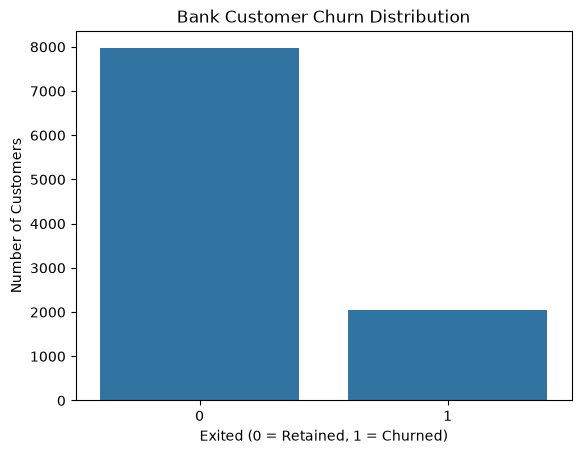

In [9]:
sns.countplot(data=df , x="Exited")

plt.title("Bank Customer Churn Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

Customer Churn rate by Gender:
Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


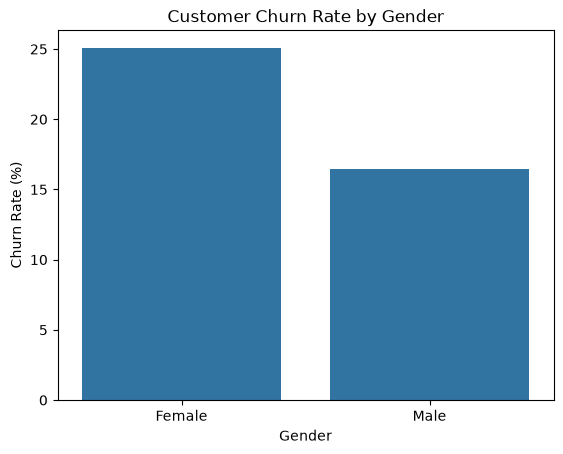

In [10]:
# Calculate churn rate by gender

gender_churn = df.groupby('Gender')['Exited'].mean() * 100

print("Customer Churn rate by Gender:")
print(gender_churn)

# Visualize the  results

plt.Figure(figsize=(7, 5))

sns.barplot(
    x=gender_churn.index,
    y=gender_churn.values
)
plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.show()

Customer Churn rate by Geography:
Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64


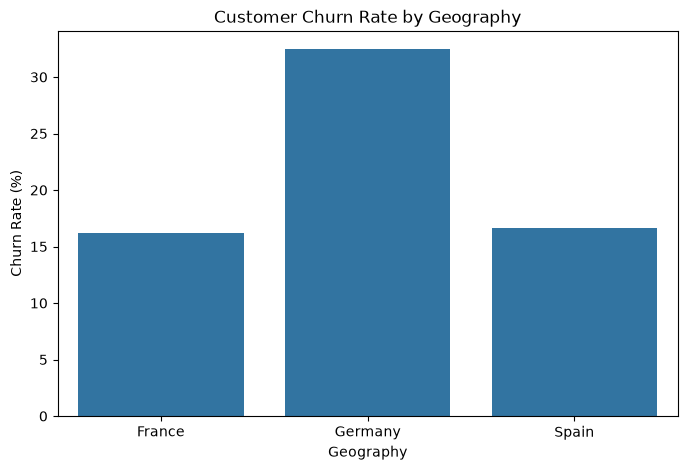

In [11]:
# Calculate churn rate by geography

geography_churn = df.groupby('Geography')['Exited'].mean() * 100

print("Customer Churn rate by Geography:")
print(geography_churn)

# Visualize the results

plt.figure(figsize=(8, 5))
sns.barplot(
    x=geography_churn.index,
    y=geography_churn.values
)
plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.show()

Customer Churn rate by Age Group:
Age_Group
18-29     7.502569
30-39    12.087171
40-49    33.965517
50-59    56.210790
60-69    31.419940
70-79     8.264463
Name: Exited, dtype: float64


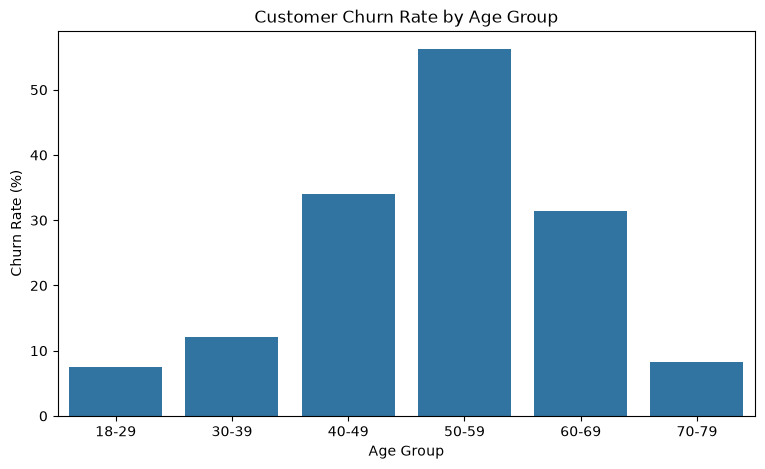

In [12]:
# Create age groups

bins = [18, 30, 40, 50, 60, 70, 80]
labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70-79']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Calculate churn rate by age group

age_churn = df.groupby('Age_Group', observed=False)['Exited'].mean() * 100

print("Customer Churn rate by Age Group:")
print(age_churn)

# Visualize the results
plt.figure(figsize=(9, 5))
sns.barplot(
    x=age_churn.index,
    y=age_churn.values
)
plt.title("Customer Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

Customer Churn rate by Credit Score Group:
Credit_Score_Group
Poor         22.147931
Fair         20.388060
Good         18.815186
Excellent    20.053763
Name: Exited, dtype: float64


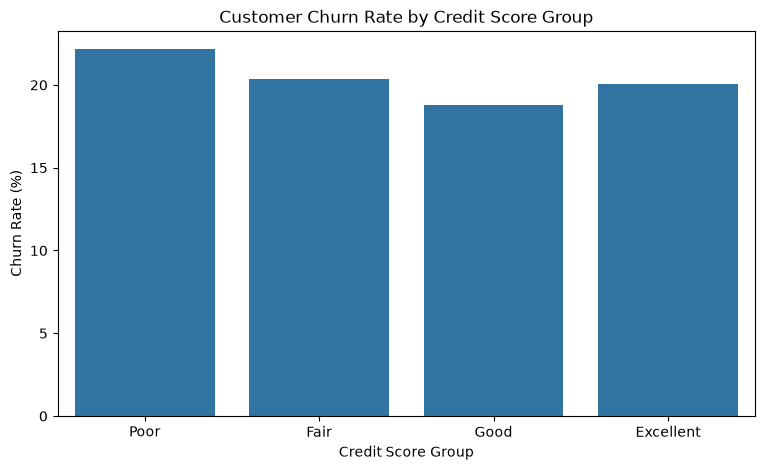

In [13]:
# Calculate churn rate by credit score group

credit_score_bins = [300, 580, 670, 740, 850]
credit_score_labels = ['Poor', 'Fair', 'Good', 'Excellent']
df['Credit_Score_Group'] = pd.cut(df['CreditScore'], bins=credit_score_bins, labels=credit_score_labels)

# Calculate churn rate by credit score group

credit_churn = df.groupby('Credit_Score_Group', observed=False)['Exited'].mean() * 100

print("Customer Churn rate by Credit Score Group:")
print(credit_churn)

# Visualize the results
plt.figure(figsize=(9, 5))
sns.barplot(
    x=credit_churn.index,
    y=credit_churn.values
)
plt.title("Customer Churn Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Churn Rate (%)")
plt.show()

Customer Churn rate by Number of Products:
NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


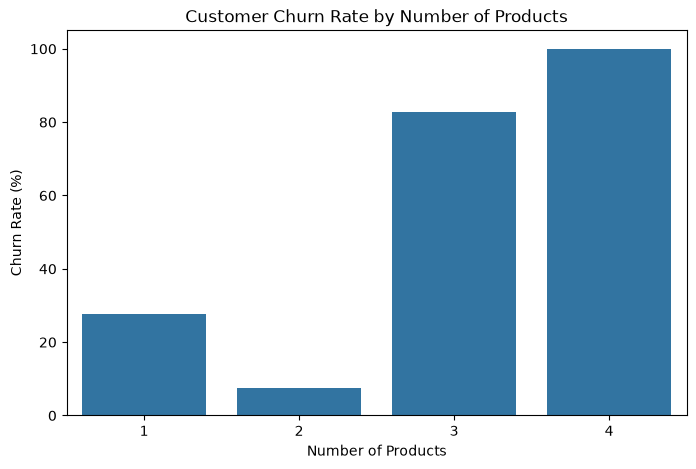

In [14]:
# Calculate churn rate by number of products

products_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100

print("Customer Churn rate by Number of Products:")
print(products_churn)

# Visualize the results
plt.figure(figsize=(8, 5))
sns.barplot(
    x=products_churn.index,
    y=products_churn.values
)
plt.title("Customer Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.show()

Customer Churn rate by Balance:
Balance_Group
Zero Balance    13.823611
0-50k           34.666667
50k-100k        19.880716
100k-150k       25.770235
150k-200k       21.925134
200k+           55.882353
Name: Exited, dtype: float64


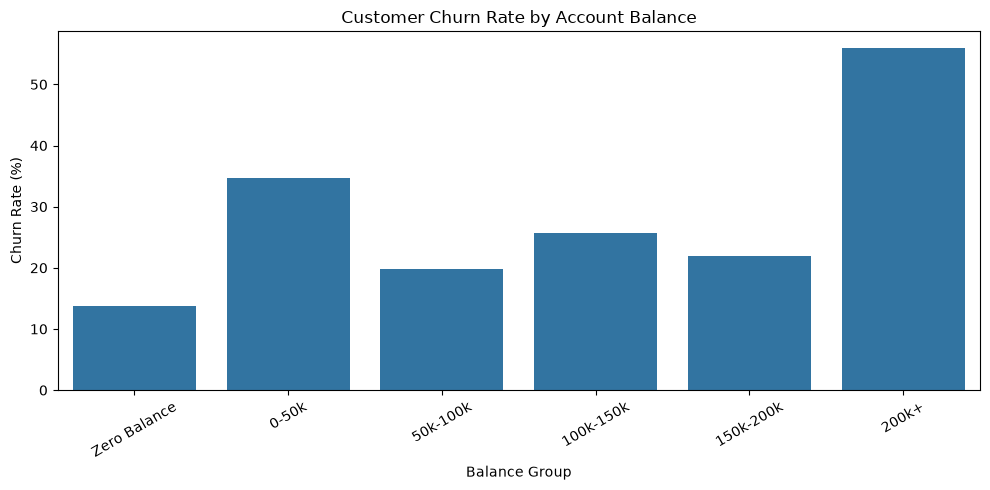

In [17]:
# Create balance groups

bins = [-1, 0, 50000, 100000, 150000, 200000, float('inf')]

lables = [
    "Zero Balance",
    "0-50k",
    "50k-100k",
    "100k-150k",
    "150k-200k",
    "200k+"
]

df['Balance_Group'] = pd.cut(df['Balance'], bins=bins, labels=lables)

# Calculate churn rate

balance_churn = df.groupby('Balance_Group', observed=False)['Exited'].mean() * 100

print("Customer Churn rate by Balance:")
print(balance_churn)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=balance_churn.index,
    y=balance_churn.values
)
plt.title("Customer Churn Rate by Account Balance")
plt.xlabel("Balance Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Customer Churn rate by Tenure:
Tenure
0     23.002421
1     22.415459
2     19.179389
3     21.110010
4     20.525784
5     20.652174
6     20.268873
7     17.217899
8     19.219512
9     21.646341
10    20.612245
Name: Exited, dtype: float64


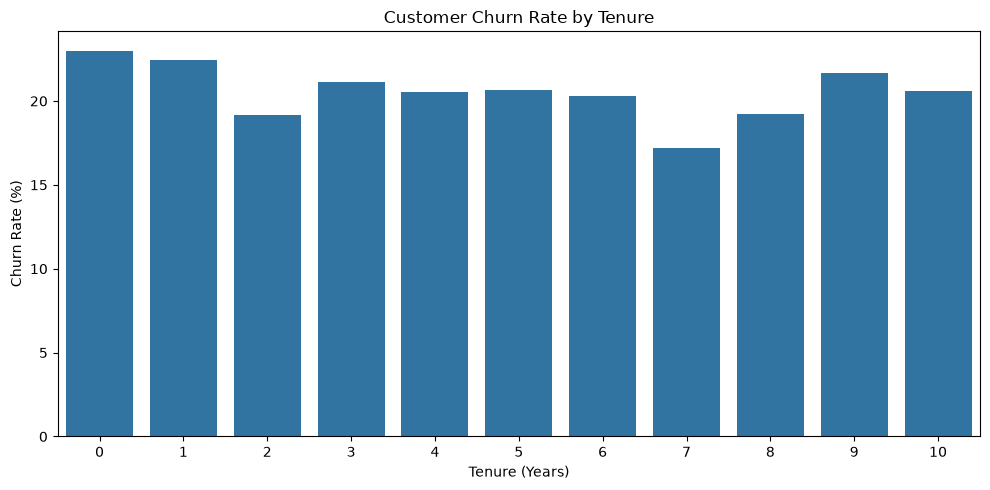

In [18]:
# Calculate churn rate by customer tenure

tenure_churn = df.groupby('Tenure')['Exited'].mean() * 100

print("Customer Churn rate by Tenure:")
print(tenure_churn)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

Customer Churn rate by Account Activity:
IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


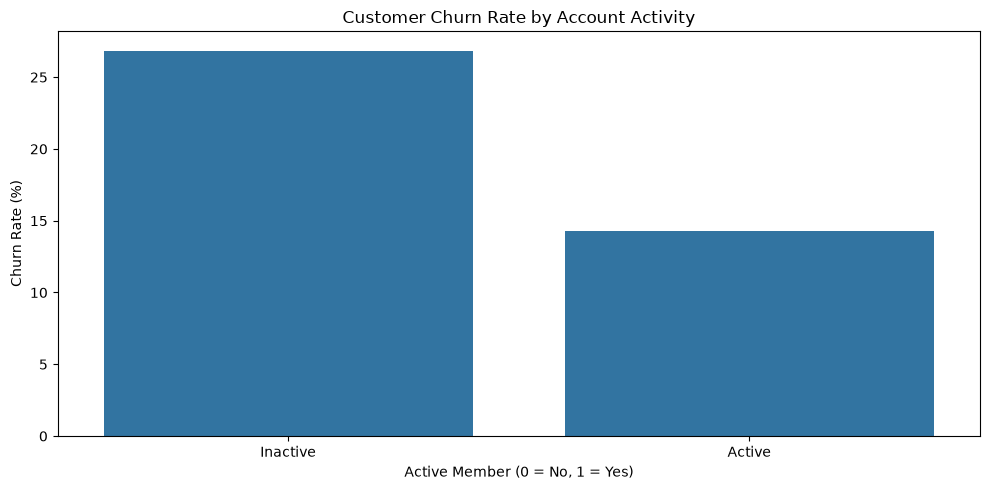

In [19]:
# Calculate churn rate by account activity

activity_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100

print("Customer Churn rate by Account Activity:")
print(activity_churn)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=activity_churn.index,
    y=activity_churn.values
)
plt.title("Customer Churn Rate by Account Activity")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks([0, 1], ["Inactive", "Active"])

plt.tight_layout()
plt.show()

Customer Churn rate by Credit Card Ownership:
HasCrCard
0    20.814941
1    20.184266
Name: Exited, dtype: float64


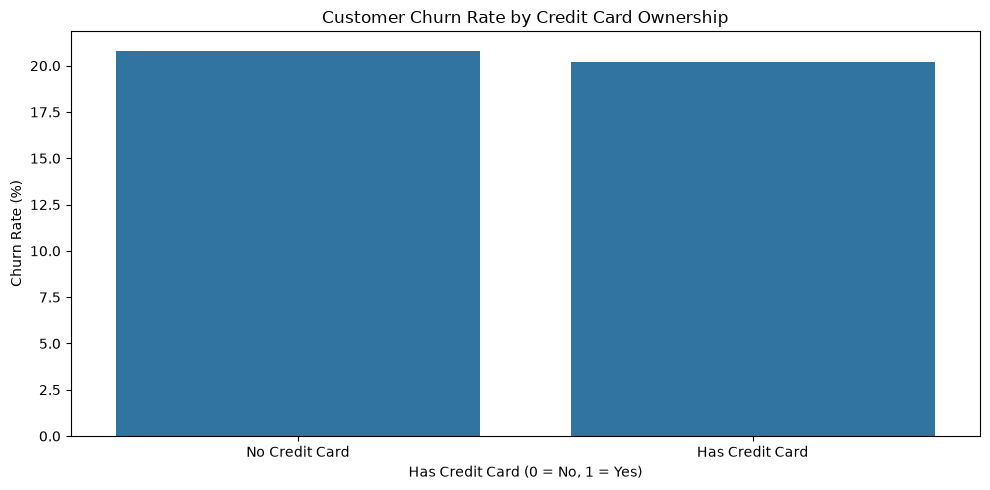

In [20]:
# Calculate churn rate by credit card ownership

credit_card_churn = df.groupby('HasCrCard')['Exited'].mean() * 100

print("Customer Churn rate by Credit Card Ownership:")
print(credit_card_churn)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=credit_card_churn.index,
    y=credit_card_churn.values
)
plt.title("Customer Churn Rate by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks([0, 1], ["No Credit Card", "Has Credit Card"])

plt.tight_layout()
plt.show()

Customer Churn rate by Estimated Salary:
Salary_Group
0-50k        19.934774
50k-100k     19.865983
100k-150k    20.234834
150k-200k    21.466395
200k+              NaN
Name: Exited, dtype: float64


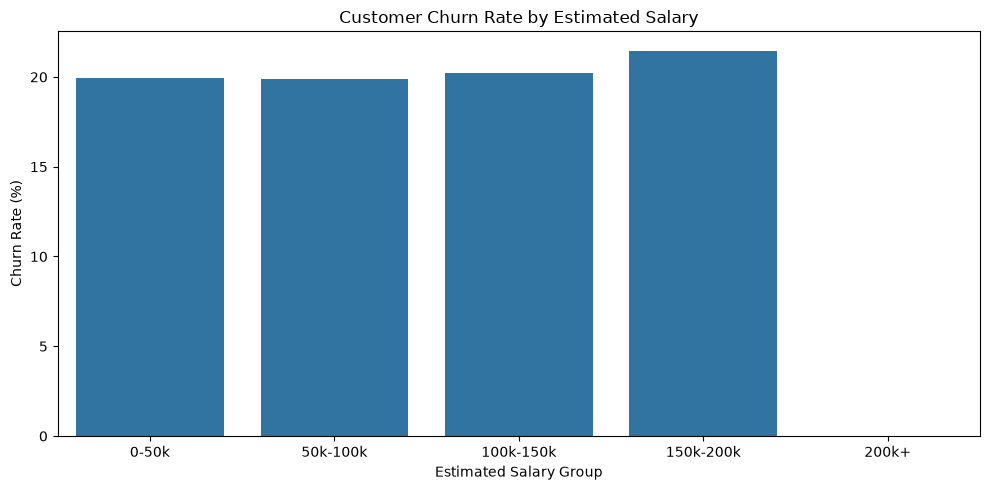

In [21]:
# Calculate churn rate by estimated salary group

salary_bins = [0, 50000, 100000, 150000, 200000, float('inf')]

salary_labels = [
    "0-50k",
    "50k-100k",
    "100k-150k",
    "150k-200k",
    "200k+"
]

df['Salary_Group'] = pd.cut(df['EstimatedSalary'], bins=salary_bins, labels=salary_labels, include_lowest=True)

salary_churn = df.groupby('Salary_Group', observed=False)['Exited'].mean() * 100

print("Customer Churn rate by Estimated Salary:")
print(salary_churn)

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(
    x=salary_churn.index,
    y=salary_churn.values
)
plt.title("Customer Churn Rate by Estimated Salary")
plt.xlabel("Estimated Salary Group")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()